# Phase 1 · Data cleaning

In this notebook we join the Olist tables and clean them so the rest of the project can rely on them. Every step that removes or aggregates rows is recorded in a cleaning log, so at the end we can see how many records were dropped and why.

**Inputs:** the 9 original CSV files in `data/raw/`, which are never modified.

**Outputs** in `data/processed/`:

| File | One row per | Used in |
|---|---|---|
| `items_clean.csv` | unit sold | products (Phase 3) and category forecast (Phase 4) |
| `orders_clean.csv` | delivered order | exploratory analysis, regions and customers (Phases 2, 5 and 6) |
| `geolocation_clean.csv` | zip code prefix | maps (Phase 5) |
| `cleaning_log.csv` | cleaning step | data quality summary |
| `olist.db` | SQLite database with the clean tables | SQL queries in Phases 2 to 6 |

We keep two main tables instead of one because they have different levels of detail. An order can include several products: if we repeated the order's total payment on every product row, summing that column would count the same payment several times.

All amounts are in Brazilian reais (R$).

## 1. Libraries and paths

Paths are built relative to the notebook folder, so the project runs on any machine without touching the code.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

DATA = Path("..") / "data"
RAW = DATA / "raw"
PROCESSED = DATA / "processed"
FIGURES = Path("..") / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)

In [2]:
# Cleaning log: every step that removes or aggregates rows is recorded here
cleaning_log = []


def log_step(table, step, rows_before, rows_after, reason):
    cleaning_log.append({
        "table": table,
        "step": step,
        "rows_before": rows_before,
        "rows_after": rows_after,
        "difference": rows_after - rows_before,
        "reason": reason,
    })

## 2. Loading the data

We read the nine files. Zip code prefixes are read as text: Brazilian zip codes can start with a zero (for example `01151`), and if they are read as numbers that zero disappears and the codes no longer match across tables.

In [3]:
orders_raw = pd.read_csv(RAW / "olist_orders_dataset.csv")
items_raw = pd.read_csv(RAW / "olist_order_items_dataset.csv")
products_raw = pd.read_csv(RAW / "olist_products_dataset.csv")
customers_raw = pd.read_csv(RAW / "olist_customers_dataset.csv", dtype={"customer_zip_code_prefix": str})
payments_raw = pd.read_csv(RAW / "olist_order_payments_dataset.csv")
reviews_raw = pd.read_csv(RAW / "olist_order_reviews_dataset.csv")
geo_raw = pd.read_csv(RAW / "olist_geolocation_dataset.csv", dtype={"geolocation_zip_code_prefix": str})
sellers_raw = pd.read_csv(RAW / "olist_sellers_dataset.csv", dtype={"seller_zip_code_prefix": str})
translation_raw = pd.read_csv(RAW / "product_category_name_translation.csv")

tables = {
    "orders": orders_raw,
    "items": items_raw,
    "products": products_raw,
    "customers": customers_raw,
    "payments": payments_raw,
    "reviews": reviews_raw,
    "geolocation": geo_raw,
    "sellers": sellers_raw,
    "category translation": translation_raw,
}

pd.DataFrame({
    "rows": {name: len(table) for name, table in tables.items()},
    "columns": {name: table.shape[1] for name, table in tables.items()},
    "duplicate_rows": {name: table.duplicated().sum() for name, table in tables.items()},
    "empty_cells": {name: table.isna().sum().sum() for name, table in tables.items()},
})

,rows,columns,duplicate_rows,empty_cells
orders,99441,8,0,4908
items,112650,7,0,0
products,32951,9,0,2448
customers,99441,5,0,0
payments,103886,5,0,0
reviews,99224,7,0,145903
geolocation,1000163,5,261831,0
sellers,3095,4,0,0
category translation,71,2,0,0


Only the geolocation table has repeated rows: 261,831 exact copies, which we handle in section 9. Next we look at which columns have empty values.

In [4]:
empty = pd.concat({name: table.isna().sum() for name, table in tables.items()}, names=["table", "column"])
empty[empty > 0].to_frame("empty_cells")

empty_cells
table    column                                    
orders   order_approved_at                      160
         order_delivered_carrier_date          1783
         order_delivered_customer_date         2965
products product_category_name                  610
         product_name_lenght                    610
         product_description_lenght             610
         product_photos_qty                     610
         product_weight_g                         2
         product_length_cm                        2
         product_height_cm                        2
         product_width_cm                         2
reviews  review_comment_title                 87656
         review_comment_message               58247

The empty values have an explanation:

- Approval, carrier and delivery dates are missing for orders that never reached those stages (canceled or still in transit).
- 610 products have no category or description, and 2 have no weight or dimensions.
- Review titles and messages are optional: 58.7% of reviews have no comment, only the score.

## 3. Orders: delivered only

Each order has a status. To measure sales we keep only delivered orders (`delivered`): a canceled order or one still in transit is not a completed sale yet, and it has no delivery date, which we need to compute delivery times and delays.

In [5]:
statuses = orders_raw["order_status"].value_counts().to_frame("orders")
statuses["share_pct"] = (statuses["orders"] / len(orders_raw) * 100).round(2)
statuses

,orders,share_pct
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


97.02% of orders were delivered. Among the rest, the largest groups are orders in transit (`shipped`, 1,107), canceled orders (625) and unavailable orders (609).

In [6]:
orders = orders_raw[orders_raw["order_status"] == "delivered"].copy()
log_step("orders", "Delivered orders only", len(orders_raw), len(orders),
         "Canceled, in transit or not shipped: not completed sales yet")

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
orders[date_columns] = orders[date_columns].apply(pd.to_datetime)
orders[date_columns].isna().sum().to_frame("empty")

,empty
order_purchase_timestamp,0
order_approved_at,14
order_delivered_carrier_date,2
order_delivered_customer_date,8
order_estimated_delivery_date,0


Among delivered orders, 8 have no delivery date. Without it we cannot compute how long the delivery took or whether it was late, so we drop them. The 14 orders without an approval date and the 2 without a carrier date stay: those dates are not used in any calculation.

In [7]:
rows_before = len(orders)
orders = orders.dropna(subset=["order_delivered_customer_date"])
log_step("orders", "Delivered without delivery date", rows_before, len(orders),
         "Delivery time and delay cannot be measured without a delivery date")
len(orders)

96470

Before computing times, we check that the dates follow a logical order.

In [8]:
purchase = orders["order_purchase_timestamp"]
delivered = orders["order_delivered_customer_date"]
carrier = orders["order_delivered_carrier_date"]
estimated = orders["order_estimated_delivery_date"]

pd.Series({
    "Delivered before purchase": (delivered < purchase).sum(),
    "Approved before purchase": (orders["order_approved_at"] < purchase).sum(),
    "Handed to carrier before purchase": (carrier < purchase).sum(),
    "Delivered before handed to carrier": (delivered < carrier).sum(),
    "Estimated date with a time other than 00:00": (estimated != estimated.dt.normalize()).sum(),
}).to_frame("orders")

,orders
Delivered before purchase,0
Approved before purchase,0
Handed to carrier before purchase,165
Delivered before handed to carrier,23
Estimated date with a time other than 00:00,0


The two dates we use to measure times, purchase and delivery, are consistent: no order appears as delivered before it was purchased. The errors are in the carrier date: 165 orders have it before the purchase and 23 appear as delivered before being handed to the carrier. Since that date is not used in any calculation, we neither fix it nor keep it in the final tables.

The estimated delivery date never has a time component (it is always 00:00). We take this into account when computing delays in section 11.

## 4. Customers: why we use `customer_unique_id`

Olist generates a new `customer_id` for every order, even when the same person places it. The identifier that represents the person is `customer_unique_id`. If we used `customer_id`, every purchase would look like a different customer and we would never find returning customers, which is exactly question 4 of the project.

In [9]:
print("Distinct customer_id:       ", customers_raw["customer_id"].nunique())
print("Distinct customer_unique_id:", customers_raw["customer_unique_id"].nunique())

Distinct customer_id:        99441
Distinct customer_unique_id: 96096


In [10]:
# A person with more than one customer_id: each one belongs to a different order
ids_per_person = customers_raw.groupby("customer_unique_id")["customer_id"].nunique()
person = ids_per_person[ids_per_person > 1].index[0]

(
    customers_raw[customers_raw["customer_unique_id"] == person]
    .merge(orders_raw[["customer_id", "order_id", "order_purchase_timestamp"]], on="customer_id")
    [["customer_unique_id", "customer_id", "order_id", "order_purchase_timestamp"]]
)

,customer_unique_id,customer_id,order_id,order_purchase_timestamp
0,00172711b30d52eea8b313a7f2cced02,1afe8a9c67eec3516c09a8bdcc539090,bb874c45df1a3c97842d52f31efee99a,2018-07-28 00:23:49
1,00172711b30d52eea8b313a7f2cced02,24b0e2bd287e47d54d193e7bbb51103f,c306eca42d32507b970739b5b6a5a33a,2018-08-13 09:14:07


The same person appears with two `customer_id` values because they placed two orders. From here on, `customer_id` is only used to join tables: it does not reach the final tables, so nobody can use it by mistake.

In [11]:
customers = customers_raw.rename(columns={"customer_zip_code_prefix": "customer_zip_prefix"})

## 5. Items: one row per unit sold

The items table has no quantity column. When someone buys two units of the same product, two rows appear with the same `product_id` and a different `order_item_id`. So the quantity sold is the number of rows, and a product's revenue is the sum of `price`: this is the "quantity × price" the proposal asks for, computed row by row.

In [12]:
units_per_product = items_raw.groupby(["order_id", "product_id"]).size()
repeated = units_per_product[units_per_product > 1]
print("Orders with more than one unit of the same product:", repeated.index.get_level_values("order_id").nunique())

example_order = repeated.index[0][0]
items_raw[items_raw["order_id"] == example_order]

Orders with more than one unit of the same product: 6968


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
13,0008288aa423d2a3f00fcb17cd7d8719,1,368c6c730842d78016ad823897a372db,1f50f920176fa81dab994f9023523100,2018-02-21 02:55:52,49.9,13.37
14,0008288aa423d2a3f00fcb17cd7d8719,2,368c6c730842d78016ad823897a372db,1f50f920176fa81dab994f9023523100,2018-02-21 02:55:52,49.9,13.37


In [13]:
print("Repeated rows by (order_id, order_item_id):", items_raw.duplicated(["order_id", "order_item_id"]).sum())
print("Prices less than or equal to zero:", (items_raw["price"] <= 0).sum())
print("Items with free shipping:", (items_raw["freight_value"] == 0).sum())

Repeated rows by (order_id, order_item_id): 0
Prices less than or equal to zero: 0
Items with free shipping: 383


In the example, the customer bought two units of the same product, which is why it appears in two rows. There are no repeated rows and no zero or negative prices. The 383 items with a freight value of 0 are free shipping, which is valid, so we leave them as they are.

## 6. Products: categories in English

Categories come in Portuguese. The dataset includes a translation table to English, `product_category_name_translation.csv`, which we use as the base. First we check that it covers every category.

In [14]:
product_categories = set(products_raw["product_category_name"].dropna())
print("Categories in the products table:", len(product_categories))
print("Missing from the translation table:", sorted(product_categories - set(translation_raw["product_category_name"])))

Categories in the products table: 73
Missing from the translation table: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


Two categories are missing, so we add them by hand. We also fix three spelling mistakes in the original translation (`costruction`, `fashio` and `confort`) and turn the names into readable labels: `health_beauty` becomes "Health beauty". The 610 products without a category are labeled "Unknown": they are real sales and we do not want to lose their revenue. Finally, we compute each product's volume (length × height × width), which sums up its size in a single number.

In [15]:
missing_translations = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["gaming_computers", "kitchen_appliances_food_processors"],
})
spelling_fixes = {"costruction": "construction", "fashio_": "fashion_", "confort": "comfort"}

translation = pd.concat([translation_raw, missing_translations], ignore_index=True)
english = translation["product_category_name_english"]
for wrong, right in spelling_fixes.items():
    english = english.str.replace(wrong, right, regex=False)
translation["category"] = english.str.replace("_", " ").str.capitalize()

assert product_categories <= set(translation["product_category_name"]), "There are categories without a translation"

products = (
    products_raw
    .merge(translation[["product_category_name", "category"]], on="product_category_name",
           how="left", validate="many_to_one")
    .assign(
        category=lambda df: df["category"].fillna("Unknown"),
        category_pt=lambda df: df["product_category_name"].fillna("unknown"),
        volume_cm3=lambda df: df["product_length_cm"] * df["product_height_cm"] * df["product_width_cm"],
    )
    .rename(columns={"product_weight_g": "weight_g"})
    [["product_id", "category", "category_pt", "weight_g", "volume_cm3"]]
)

sellers = sellers_raw.rename(columns={"seller_zip_code_prefix": "seller_zip_prefix"})

products.head()

,product_id,category,category_pt,weight_g,volume_cm3
0,1e9e8ef04dbcff4541ed26657ea517e5,Perfumery,perfumaria,225.0,2240.0
1,3aa071139cb16b67ca9e5dea641aaa2f,Art,artes,1000.0,10800.0
2,96bd76ec8810374ed1b65e291975717f,Sports leisure,esporte_lazer,154.0,2430.0
3,cef67bcfe19066a932b7673e239eb23d,Baby,bebes,371.0,2704.0
4,9dc1a7de274444849c219cff195d0b71,Housewares,utilidades_domesticas,625.0,4420.0


## 7. Payments: an order can have several

An order can be paid with more than one method, for example part with a credit card and the rest with vouchers, and each payment is a row. If we joined this table directly with the items, an order with 3 payments and 2 products would produce 6 rows and revenue would be overcounted. So we first aggregate it to one row per order.

In [16]:
payments_per_order = payments_raw.groupby("order_id").size()
print("Orders with more than one payment:", (payments_per_order > 1).sum())
print("Maximum number of payments in a single order:", payments_per_order.max())

example_order = payments_per_order[payments_per_order > 2].index[0]
payments_raw[payments_raw["order_id"] == example_order].sort_values("payment_sequential")

Orders with more than one payment: 2961
Maximum number of payments in a single order: 29


,order_id,payment_sequential,payment_type,payment_installments,payment_value
16053,009ac365164f8e06f59d18a08045f6c4,1,credit_card,1,0.88
16459,009ac365164f8e06f59d18a08045f6c4,2,voucher,1,4.50
73837,009ac365164f8e06f59d18a08045f6c4,3,voucher,1,8.25
32058,009ac365164f8e06f59d18a08045f6c4,4,voucher,1,5.45
285,009ac365164f8e06f59d18a08045f6c4,5,voucher,1,8.75
15298,009ac365164f8e06f59d18a08045f6c4,6,voucher,1,4.17


This order was paid in six parts: one by credit card and five with vouchers.

For each order we compute the total paid, the maximum number of installments and the main payment method, which is the one covering the largest amount. We also give the payment methods readable names. A *boleto* is a bank slip paid in cash at banks or stores, widely used in Brazil.

In [17]:
payment_names = {
    "credit_card": "Credit card",
    "boleto": "Boleto",
    "voucher": "Voucher",
    "debit_card": "Debit card",
    "not_defined": "Not defined",
}
payments = payments_raw.assign(payment_type=payments_raw["payment_type"].map(payment_names))

# Main method: the largest payment within each order
main_method = (
    payments.sort_values("payment_value", ascending=False, kind="stable")
    .drop_duplicates("order_id")
    .set_index("order_id")["payment_type"]
)

payments_by_order = payments.groupby("order_id").agg(
    payment_total=("payment_value", "sum"),
    installments=("payment_installments", "max"),
)
payments_by_order["payment_type"] = main_method

log_step("payments", "One row per order", len(payments_raw), len(payments_by_order),
         "Payments of the same order are added up so amounts are not duplicated when joining")
payments_by_order.head()

,payment_total,installments,payment_type
order_id,,,
00010242fe8c5a6d1ba2dd792cb16214,72.19,2,Credit card
00018f77f2f0320c557190d7a144bdd3,259.83,3,Credit card
000229ec398224ef6ca0657da4fc703e,216.87,5,Credit card
00024acbcdf0a6daa1e931b038114c75,25.78,2,Credit card
00042b26cf59d7ce69dfabb4e55b4fd9,218.04,3,Credit card


## 8. Reviews: one per order

After delivery, Olist sends the customer a survey with a score from 1 to 5 and an optional comment. Some orders have more than one review; in that case we keep the most recent answer, which reflects the customer's final opinion.

In [18]:
reviews_per_order = reviews_raw.groupby("order_id").size()
print("Orders with more than one review:", (reviews_per_order > 1).sum())
print("review_id repeated across different orders:", reviews_raw["review_id"].duplicated().sum())

example_order = reviews_per_order[reviews_per_order > 1].index[0]
reviews_raw.loc[
    reviews_raw["order_id"] == example_order,
    ["review_id", "order_id", "review_score", "review_creation_date", "review_answer_timestamp"],
]

Orders with more than one review: 547
review_id repeated across different orders: 814


,review_id,order_id,review_score,review_creation_date,review_answer_timestamp
22423,2a74b0559eb58fc1ff842ecc999594cb,0035246a40f520710769010f752e7507,5,2017-08-25 00:00:00,2017-08-29 21:45:57
25612,89a02c45c340aeeb1354a24e7d4b2c1e,0035246a40f520710769010f752e7507,5,2017-08-29 00:00:00,2017-08-30 01:59:12


In the example, the customer rated the same order twice. Besides the score, we keep whether the customer left a written comment and the review date. That date will help us in Phase 6 to make sure the model only uses information available at prediction time.

The repeated `review_id` values are reviews linked to more than one order. Since we work at the order level, they do not create duplicates.

In [19]:
reviews = (
    reviews_raw
    .assign(
        review_creation_date=lambda df: pd.to_datetime(df["review_creation_date"]),
        review_answer_timestamp=lambda df: pd.to_datetime(df["review_answer_timestamp"]),
    )
    .sort_values("review_answer_timestamp", kind="stable")
    .drop_duplicates("order_id", keep="last")
    .assign(has_comment=lambda df: df["review_comment_message"].notna())
    .rename(columns={"review_creation_date": "review_date"})
    [["order_id", "review_score", "has_comment", "review_date"]]
)

log_step("reviews", "One review per order", len(reviews_raw), len(reviews),
         "Orders with several reviews keep the most recent answer")
len(reviews)

98673

## 9. Geolocation: one point per zip code prefix

This table has over a million rows for about 19,000 zip code prefixes: each prefix appears many times, and 261,831 rows are exact copies. If we joined it as is, each customer would be multiplied by all the rows of their prefix.

We reduce it to a single point per prefix using the median latitude and longitude. We use the median rather than the mean because extreme coordinates do not pull it. Before that, we drop points that fall outside the rectangle enclosing Brazil, which are data entry errors.

In [20]:
print("Rows:", len(geo_raw))
print("Distinct zip code prefixes:", geo_raw["geolocation_zip_code_prefix"].nunique())

# Rectangle defined by Brazil's northernmost, southernmost, westernmost and easternmost points
inside_brazil = (
    geo_raw["geolocation_lat"].between(-33.75, 5.27)
    & geo_raw["geolocation_lng"].between(-73.99, -34.79)
)
print("Points outside Brazil:", (~inside_brazil).sum())

geolocation = (
    geo_raw[inside_brazil]
    .groupby("geolocation_zip_code_prefix", as_index=False)
    .agg(lat=("geolocation_lat", "median"), lng=("geolocation_lng", "median"))
    .rename(columns={"geolocation_zip_code_prefix": "zip_prefix"})
)

log_step("geolocation", "Points outside Brazil", len(geo_raw), int(inside_brazil.sum()),
         "Impossible coordinates for Brazilian addresses: data entry errors")
log_step("geolocation", "One point per zip code prefix", int(inside_brazil.sum()), len(geolocation),
         "Median latitude and longitude of each prefix")
geolocation.head()

Rows: 1000163
Distinct zip code prefixes: 19015
Points outside Brazil: 42


,zip_prefix,lat,lng
0,01001,-23.550381,-46.634027
1,01002,-23.548551,-46.635072
2,01003,-23.548977,-46.635313
3,01004,-23.549535,-46.634771
4,01005,-23.549612,-46.636532


## 10. Items table

We join each item with its order, customer, product and seller. In every join we set `validate="many_to_one"`: pandas checks that the right side has a single row per key and stops with an error otherwise. This guarantees that no join duplicates rows.

The join with orders is `inner`: only items from delivered orders survive.

In [21]:
items = (
    items_raw
    .merge(orders[["order_id", "customer_id", "order_purchase_timestamp"]],
           on="order_id", how="inner", validate="many_to_one")
    .merge(customers[["customer_id", "customer_unique_id", "customer_state"]],
           on="customer_id", how="left", validate="many_to_one")
    .merge(products, on="product_id", how="left", validate="many_to_one")
    .merge(sellers[["seller_id", "seller_state", "seller_zip_prefix"]],
           on="seller_id", how="left", validate="many_to_one")
)
log_step("items", "Items from delivered orders only", len(items_raw), len(items),
         "Items from orders that were not delivered are not sales")

items_clean = items.rename(columns={"order_purchase_timestamp": "purchase_date"})[[
    "order_id", "order_item_id", "product_id", "seller_id", "customer_unique_id", "purchase_date",
    "category", "category_pt", "price", "freight_value", "weight_g", "volume_cm3",
    "customer_state", "seller_state", "seller_zip_prefix",
]]
items_clean.head()

,order_id,order_item_id,product_id,seller_id,customer_unique_id,purchase_date,category,category_pt,price,freight_value,weight_g,volume_cm3,customer_state,seller_state,seller_zip_prefix
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,871766c5855e863f6eccc05f988b23cb,2017-09-13 08:59:02,Cool stuff,cool_stuff,58.90,13.29,650.0,3528.0,RJ,SP,27277
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,eb28e67c4c0b83846050ddfb8a35d051,2017-04-26 10:53:06,Pet shop,pet_shop,239.90,19.93,30000.0,60000.0,SP,SP,03471
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,3818d81c6709e39d06b2738a8d3a2474,2018-01-14 14:33:31,Furniture decor,moveis_decoracao,199.00,17.87,3050.0,14157.0,MG,MG,37564
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,af861d436cfc08b2c2ddefd0ba074622,2018-08-08 10:00:35,Perfumery,perfumaria,12.99,12.79,200.0,2400.0,SP,SP,14403
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,64b576fb70d441e8f1b2d7d446e483c5,2017-02-04 13:57:51,Garden tools,ferramentas_jardim,199.90,18.14,3750.0,42000.0,SP,PR,87900


## 11. Orders table and new columns

We aggregate the items by order and add the customer, payment and review information. The new columns are:

| Column | Calculation |
|---|---|
| `revenue` | sum of item prices, excluding freight |
| `freight_value` | sum of item freight |
| `total_value` | `revenue` + `freight_value`: what the customer paid for the order |
| `main_category` | category of the most expensive item in the order |
| `delivery_days` | calendar days between purchase and delivery |
| `delay_days` | calendar days between the estimated and the actual delivery date; a negative value means the order arrived early |
| `is_late` | true when `delay_days` is greater than 0 |

We compare calendar days because the estimated date has no time. An order delivered on the estimated day, at any time, arrived on time.

In [22]:
items_by_order = items_clean.groupby("order_id").agg(
    units=("order_item_id", "count"),
    revenue=("price", "sum"),
    freight_value=("freight_value", "sum"),
)

# The main category of an order is the category of its most expensive item
main_category = (
    items_clean.sort_values("price", ascending=False, kind="stable")
    .drop_duplicates("order_id")
    .set_index("order_id")["category"]
    .rename("main_category")
)

orders_clean = (
    orders
    .merge(customers, on="customer_id", how="left", validate="one_to_one")
    .merge(items_by_order, left_on="order_id", right_index=True, how="left", validate="one_to_one")
    .merge(main_category, left_on="order_id", right_index=True, how="left", validate="one_to_one")
    .merge(payments_by_order, left_on="order_id", right_index=True, how="left", validate="one_to_one")
    .merge(reviews, on="order_id", how="left", validate="one_to_one")
    .rename(columns={
        "order_purchase_timestamp": "purchase_date",
        "order_delivered_customer_date": "delivered_date",
        "order_estimated_delivery_date": "estimated_date",
    })
)

purchase_day = orders_clean["purchase_date"].dt.normalize()
delivery_day = orders_clean["delivered_date"].dt.normalize()

orders_clean["total_value"] = orders_clean["revenue"] + orders_clean["freight_value"]
orders_clean["delivery_days"] = (delivery_day - purchase_day).dt.days
orders_clean["delay_days"] = (delivery_day - orders_clean["estimated_date"]).dt.days
orders_clean["is_late"] = orders_clean["delay_days"] > 0

# Nullable types keep integers as integers when there are empty values (5, not 5.0)
orders_clean = orders_clean.astype({
    "review_score": "Int64",
    "installments": "Int64",
    "has_comment": "boolean",
})

orders_clean = orders_clean[[
    "order_id", "customer_unique_id", "purchase_date", "delivered_date", "estimated_date",
    "units", "revenue", "freight_value", "total_value", "main_category",
    "payment_total", "payment_type", "installments",
    "delivery_days", "delay_days", "is_late",
    "review_score", "has_comment", "review_date",
    "customer_city", "customer_state", "customer_zip_prefix",
]]
orders_clean.head()

,order_id,customer_unique_id,purchase_date,delivered_date,estimated_date,units,revenue,freight_value,total_value,main_category,payment_total,payment_type,installments,delivery_days,delay_days,is_late,review_score,has_comment,review_date,customer_city,customer_state,customer_zip_prefix
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,1,29.99,8.72,38.71,Housewares,38.71,Voucher,1,8,-8,False,4,True,2017-10-11,sao paulo,SP,03149
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,1,118.70,22.76,141.46,Perfumery,141.46,Boleto,1,14,-6,False,4,True,2018-08-08,barreiras,BA,47813
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,1,159.90,19.22,179.12,Auto,179.12,Credit card,3,9,-18,False,5,False,2018-08-18,vianopolis,GO,75265
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,1,45.00,27.20,72.20,Pet shop,72.20,Credit card,1,14,-13,False,5,True,2017-12-03,sao goncalo do amarante,RN,59296
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,1,19.90,8.72,28.62,Stationery,28.62,Credit card,1,3,-10,False,5,False,2018-02-17,santo andre,SP,09195


## 12. Final checks

These checks stop the notebook with an error if something does not add up (`assert`). If the notebook is later run with the business data, any problem shows up here instead of when the dashboard is already being built.

In [23]:
checks = pd.Series({
    "order_id is unique in the orders table": orders_clean["order_id"].is_unique,
    "(order_id, order_item_id) is unique in the items table":
        not items_clean.duplicated(["order_id", "order_item_id"]).any(),
    "Every item belongs to a clean order": items_clean["order_id"].isin(orders_clean["order_id"]).all(),
    "Every order has at least one item": orders_clean["units"].notna().all(),
    "Total revenue matches between both tables":
        np.isclose(items_clean["price"].sum(), orders_clean["revenue"].sum()),
    "Every item has a customer and a category": items_clean[["customer_unique_id", "category"]].notna().all().all(),
    "No order has negative delivery days": (orders_clean["delivery_days"] >= 0).all(),
})
assert checks.all(), checks[~checks]
checks.to_frame("passed")

,passed
order_id is unique in the orders table,True
"(order_id, order_item_id) is unique in the items table",True
Every item belongs to a clean order,True
Every order has at least one item,True
Total revenue matches between both tables,True
Every item has a customer and a category,True
No order has negative delivery days,True


All checks pass. These are the empty values left in the final tables:

In [24]:
empty_final = pd.concat(
    {"orders": orders_clean.isna().sum(), "items": items_clean.isna().sum()},
    names=["table", "column"],
)
empty_final[empty_final > 0].to_frame("empty")

empty
table  column              
orders payment_total      1
       payment_type       1
       installments       1
       review_score     646
       has_comment      646
       review_date      646
items  weight_g          18
       volume_cm3        18

In [25]:
payment_gap = (orders_clean["payment_total"] - orders_clean["total_value"]).abs()
print(f"Orders whose payment matches price + freight (within R$ 1): {(payment_gap <= 1).mean():.1%}")

without_coordinates = ~orders_clean["customer_zip_prefix"].isin(geolocation["zip_prefix"])
print("Orders whose zip code prefix has no coordinates:", without_coordinates.sum())

Orders whose payment matches price + freight (within R$ 1): 99.7%
Orders whose zip code prefix has no coordinates: 265


The remaining empty values are few and have an explanation, so we keep those orders:

- 646 orders have no review because the customer did not answer the survey. The sale still happened; in Phase 6 we will decide how to handle them in the model.
- 1 order has no payment record. It is a single case, and its revenue is still computed from its items.
- 18 items have no weight or volume: they belong to the 2 products without dimensions.

The total paid matches price + freight in 99.7% of orders, which confirms that multiple payments were aggregated correctly. Finally, 265 orders have a zip code prefix without coordinates: they will not appear on the Phase 5 maps, but they are included in every other analysis.

## 13. Delivered orders per month

Before finishing, we look at how orders are distributed over time, because the Phase 4 forecast depends on it. First the table (years in rows, months in columns), then the chart.

In [26]:
per_month = (
    orders_clean.groupby(orders_clean["purchase_date"].dt.to_period("M"))
    .size()
    .reindex(pd.period_range("2016-09", "2018-08", freq="M"), fill_value=0)
)

per_month.to_frame("orders").assign(
    year=lambda df: df.index.year,
    month=lambda df: df.index.month,
).pivot(index="year", columns="month", values="orders").astype("Int64")

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2016,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1,265,0,1
2017,750,1653,2546,2303,3545,3135,3872,4193,4150,4478,7288,5513
2018,7069,6555,7003,6798,6749,6096,6156,6351,<NA>,<NA>,<NA>,<NA>


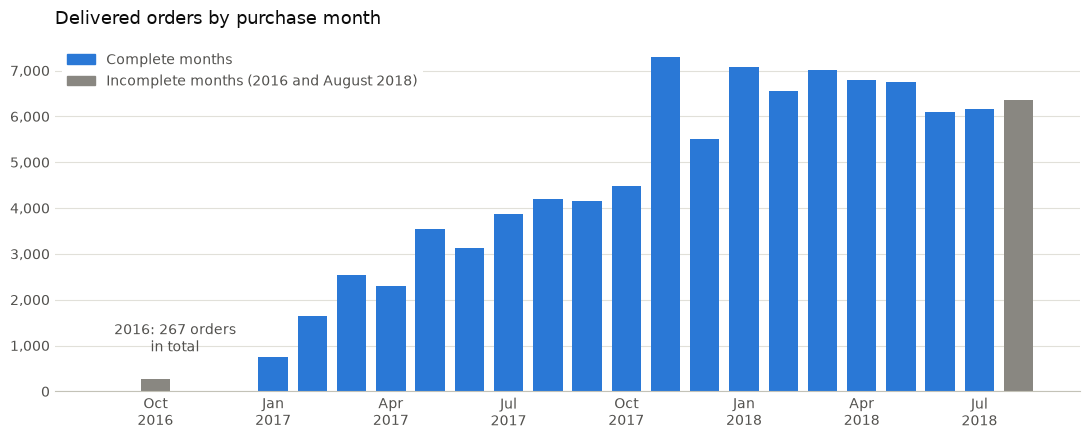

In [27]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
BLUE, GRAY = "#2a78d6", "#898781"
INK, SECONDARY_INK, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"

is_2016 = per_month.index.year == 2016
incomplete = is_2016 | (per_month.index == pd.Period("2018-08", freq="M"))
positions = np.arange(len(per_month))
labels = [f"{MONTHS[p.month - 1]}\n{p.year}" if p.month in (1, 4, 7, 10) else "" for p in per_month.index]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(positions, per_month.to_numpy(), color=np.where(incomplete, GRAY, BLUE), width=0.75)

ax.set_title("Delivered orders by purchase month", loc="left", fontsize=13, color=INK, pad=12)
ax.set_xticks(positions, labels)
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.tick_params(colors=SECONDARY_INK, length=0)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)

total_2016 = per_month[is_2016].sum()
ax.text(1.5, per_month.max() * 0.12, f"2016: {total_2016} orders\nin total", ha="center", color=SECONDARY_INK)
ax.legend(
    handles=[Patch(color=BLUE, label="Complete months"),
             Patch(color=GRAY, label="Incomplete months (2016 and August 2018)")],
    loc="upper left", labelcolor=SECONDARY_INK,
    frameon=True, facecolor="white", edgecolor="none", framealpha=1,
)
plt.tight_layout()
fig.savefig(FIGURES / "01_orders_per_month.png", dpi=150, bbox_inches="tight")
plt.show()

The chart shows three things that shape the Phase 4 forecast:

- 2016 has almost no data: 267 delivered orders in total, almost all of them in October, and none in November. Those months do not represent normal operations, so the forecasting series starts in January 2017.
- August 2018 is the last month with delivered orders and, as the next table shows, it is incomplete.
- November 2017 is the highest month, with 7,288 orders. The peak is concentrated on Black Friday: 1,147 orders were placed on November 24, while the median day that month had 183. We look at this in detail in Phase 2.

To see what happens at the end of the dataset, we count the orders placed each day of August 2018, in any status, and compare them with the same weekday of the previous week. We use the original orders table rather than the clean one: this tells us whether the drop comes from sales or from the data.

In [28]:
purchase_day_raw = pd.to_datetime(orders_raw["order_purchase_timestamp"]).dt.normalize()
per_day_raw = (
    purchase_day_raw.value_counts()
    .sort_index()
    .reindex(pd.date_range("2018-08-01", "2018-08-31"), fill_value=0)
)
dataset_end = pd.DataFrame({
    "orders_any_status": per_day_raw,
    "same_weekday_previous_week": per_day_raw.shift(7),
})
dataset_end["change_pct"] = (dataset_end["orders_any_status"] / dataset_end["same_weekday_previous_week"] - 1) * 100
dataset_end.loc["2018-08-15":].round(0)

,orders_any_status,same_weekday_previous_week,change_pct
2018-08-15,288,316.0,-9.0
2018-08-16,320,289.0,11.0
2018-08-17,257,256.0,0.0
2018-08-18,198,188.0,5.0
2018-08-19,204,197.0,4.0
2018-08-20,256,292.0,-12.0
2018-08-21,243,316.0,-23.0
2018-08-22,187,288.0,-35.0
2018-08-23,144,320.0,-55.0
2018-08-24,99,257.0,-61.0


Up to August 21, daily orders vary within the usual range compared with the previous week. From August 22 on, every day has at least 35% fewer orders than the same weekday of the previous week, and the drop reaches 99% on the 31st. Since this happens to orders in every status, it is not a drop in sales: it is the end of the available data.

That is why we treat August 2018 as an incomplete month. Reliable data runs through August 21, and Phase 2 uses that date as the limit for daily averages.

## 14. Cleaning log

This is the data quality summary: each row is a step that removed or aggregated records, along with the reason.

In [29]:
cleaning_log = pd.DataFrame(cleaning_log)
cleaning_log

,table,step,rows_before,rows_after,difference,reason
0,orders,Delivered orders only,99441,96478,-2963,"Canceled, in transit or not shipped: not completed sales yet"
1,orders,Delivered without delivery date,96478,96470,-8,Delivery time and delay cannot be measured without a delivery date
2,payments,One row per order,103886,99440,-4446,Payments of the same order are added up so amounts are not duplicated when joining
3,reviews,One review per order,99224,98673,-551,Orders with several reviews keep the most recent answer
4,geolocation,Points outside Brazil,1000163,1000121,-42,Impossible coordinates for Brazilian addresses: data entry errors
5,geolocation,One point per zip code prefix,1000121,19010,-981111,Median latitude and longitude of each prefix
6,items,Items from delivered orders only,112650,110189,-2461,Items from orders that were not delivered are not sales


## 15. Saving

We save the four tables in `data/processed/`.

In [30]:
outputs = {
    "items_clean.csv": items_clean,
    "orders_clean.csv": orders_clean,
    "geolocation_clean.csv": geolocation,
    "cleaning_log.csv": cleaning_log,
}
for name, table in outputs.items():
    table.to_csv(PROCESSED / name, index=False)
    print(f"{name:<24} {len(table):>8,} rows")

items_clean.csv           110,189 rows


orders_clean.csv           96,470 rows
geolocation_clean.csv      19,010 rows
cleaning_log.csv                7 rows


We also load the clean tables into a SQLite database, `olist.db`. SQLite comes with Python and needs no server, and from Phase 2 on we use it to answer the business questions with SQL, the standard language for querying company data. The CSV files stay because Power BI reads them directly.

In [31]:
DATABASE = PROCESSED / "olist.db"
connection = sqlite3.connect(DATABASE)
for name, table in {"orders": orders_clean, "items": items_clean, "geolocation": geolocation}.items():
    table.to_sql(name, connection, if_exists="replace", index=False)

# Indexes speed up the filters and joins used in the next phases
connection.executescript('''
    CREATE INDEX IF NOT EXISTS idx_orders_customer ON orders (customer_unique_id);
    CREATE INDEX IF NOT EXISTS idx_orders_purchase_date ON orders (purchase_date);
    CREATE INDEX IF NOT EXISTS idx_items_order ON items (order_id);
    CREATE INDEX IF NOT EXISTS idx_items_purchase_date ON items (purchase_date);
''')

row_counts = pd.read_sql_query('''
    SELECT 'orders' AS table_name, COUNT(*) AS row_count FROM orders
    UNION ALL
    SELECT 'items', COUNT(*) FROM items
    UNION ALL
    SELECT 'geolocation', COUNT(*) FROM geolocation
''', connection)
connection.close()
row_counts

,table_name,row_count
0,orders,96470
1,items,110189
2,geolocation,19010


## 16. Summary of the clean data

In [32]:
orders_per_customer = orders_clean.groupby("customer_unique_id").size()
returning = orders_per_customer > 1

pd.Series({
    "Period (purchase date)": f"{orders_clean['purchase_date'].min():%Y-%m-%d} to {orders_clean['purchase_date'].max():%Y-%m-%d}",
    "Delivered orders": f"{len(orders_clean):,}",
    "Units sold": f"{len(items_clean):,}",
    "Distinct products": f"{items_clean['product_id'].nunique():,}",
    "Categories (including Unknown)": items_clean["category"].nunique(),
    "Distinct customers": f"{len(orders_per_customer):,}",
    "Customers with more than one order": f"{returning.sum():,} ({returning.mean():.1%})",
    "Product revenue": f"R$ {orders_clean['revenue'].sum():,.0f}",
    "Median delivery days": f"{orders_clean['delivery_days'].median():.0f}",
    "Orders delivered late": f"{orders_clean['is_late'].mean():.2%}",
}).to_frame("value")

,value
Period (purchase date),2016-09-15 to 2018-08-29
Delivered orders,"96,470"
Units sold,"110,189"
Distinct products,"32,214"
Categories (including Unknown),74
Distinct customers,"93,350"
Customers with more than one order,"2,801 (3.0%)"
Product revenue,"R$ 13,220,249"
Median delivery days,10
Orders delivered late,6.77%


## Key insights

- Out of 99,441 original orders, 96,470 remain: the delivered orders with a delivery date. They contain 110,189 units of 32,214 different products, worth R$ 13.2 million excluding freight.
- We handled the four dataset traps that could inflate the numbers when joining tables: a different `customer_id` for every order, multiple payments, repeated reviews and a geolocation table with many rows per zip code prefix. The checks in section 12 confirm that no join duplicated rows.
- There are 93,350 distinct customers and only 2,801 (3.0%) bought more than once. This imbalance is key for Phase 6: a model that always answered "will not return" would be right about 97% of the time without learning anything. That is why we will evaluate it with AUC, precision and recall rather than accuracy.
- The median delivery time is 10 days, and 6.77% of orders arrived after the estimated date.
- For the forecast there are 19 complete months, from January 2017 to July 2018. August 2018 is incomplete because the data stops being complete on August 22. With less than two years of data it is hard to estimate a yearly pattern, and we will take that into account when choosing the models.

The details of every cleaning step are in the cleaning log (section 14), also saved as `data/processed/cleaning_log.csv`.